# Motifs with median gap at least 0.1

This dictionary keeps every motif from `SOCAL_H_76_230427_014845.x.limited_overlap_m8x32_refine2_drop_runners` whose median residual gap is at least 0.1. Eight motifs remain: 0, 1, 10, 11, 13, 14, 17, and 44. Motif 3 is removed; its median gap is 0.043. The atoms and placements of the eight motifs are unchanged.

The residual is the unexplained fraction after the mean plus five components. The gap at a placement is the runner-up residual minus the assigned motif's residual.

Output directory: `/home/yfreund/whale_processing/result/LeiData/SOCAL_H_76_230427_014845.x.limited_overlap_m8x32_refine2_gap01`.


In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

from analysis.GPL_Python.gpl_outputs import display_from_spwhiten
from analysis.dict_learning.code.io import discover_windows
from analysis.evaluation.core import (
    _dot_products,
    _load_basis,
    _peak_ratios,
    _residual_summary,
    _specificity_p90,
)

OUT = Path(
    "/home/yfreund/whale_processing/result/LeiData/"
    "SOCAL_H_76_230427_014845.x.limited_overlap_m8x32_refine2_gap01"
)
GPL = Path(
    "/home/yfreund/whale_processing/result/LeiData/"
    "SOCAL_H_76_230427_014845.x.gpl/output/spectrogram_npy"
)
summary = json.loads((OUT / "summary.json").read_text())
matchings = json.loads((OUT / "matchings.json").read_text())
counts = np.load(OUT / "counts.npz")
windows = discover_windows(GPL)
windows.sort(key=lambda window: (window.start_sample, window.window_id))
sec_per_bin = float(windows[0].overlap) / float(windows[0].sample_freq)

offsets = {}
parts = []
cursor = 0
for window in windows:
    data = np.asarray(window.data, dtype=np.float64)
    offsets[window.window_id] = cursor
    parts.append(data)
    cursor += data.shape[1]
spectrogram = np.concatenate(parts, axis=1)

freq_axis = np.linspace(0.0, float(windows[0].sample_freq) / 2.0, int(windows[0].fftl) // 2)
i0 = int(np.argmin(np.abs(freq_axis - float(windows[0].start_freq))))
freqs = freq_axis[i0 : i0 + spectrogram.shape[0]]
band = np.flatnonzero(freqs <= 1500.0)
band_lo, band_hi = int(band[0]), int(band[-1]) + 1
f_lo, f_hi = float(freqs[band_lo]), float(freqs[band_hi - 1])

counts_kept = [row["n_placements"] for row in summary["motifs"]]
ratio = max(counts_kept) / min(counts_kept)
print(f"kept {summary['kept_motifs']}")
print(
    f"coverage {summary['coverage']:.3f}  "
    f"({summary['n_bins_covered']} / {summary['n_bins_total']} columns)  "
    f"motifs {summary['n_motifs']}  placements {summary['n_placements']}  "
    f"max count {summary['max_count']}"
)
print(f"placement counts {min(counts_kept)} to {max(counts_kept)}  ratio {ratio:.3f}")


kept [0, 1, 10, 11, 13, 14, 17, 44]
coverage 0.114  (2075 / 18270 columns)  motifs 8  placements 166  max count 1
placement counts 10 to 50  ratio 5.000


## Residual and runner-up

Each motif is scored again against the eight that remain. The median residual and the median gap are taken over the motif's own placements. The runner-up column is the motif that has the smallest residual most often.


In [2]:
models = {row["motif_id"]: _load_basis(str(OUT / row["path"])) for row in summary["motifs"]}
widths = {row["motif_id"]: int(row["width"]) for row in summary["motifs"]}
placements = [
    (row["motif_id"], offsets[row["window_id"]] + int(row["t_start"]), widths[row["motif_id"]])
    for row in matchings
]
scored = _residual_summary(spectrogram, offsets, placements, models)
print(
    f"coverage ratio {scored['coverage_ratio']:.3f}  "
    f"placement ratio {scored['placement_ratio']:.3f}  "
    f"minimum mean gap {scored['min_gap']:.3f}"
)
print(f"{'motif':>6} {'n':>4} {'median residual':>16} {'median gap':>12} {'runner-up':>10}")
for motif_id, row in sorted(scored["motifs"].items()):
    print(
        f"{motif_id:6d} {row['n_placements']:4d} "
        f"{row['residual_median']:16.4f} {row['gap_median']:12.4f} {row['runner_id']:10d}"
    )
below = [motif_id for motif_id, row in scored["motifs"].items() if row["gap_median"] < 0.1]
print(f"motifs with median gap below 0.1: {sorted(below)}")


coverage ratio 3.571  placement ratio 5.000  minimum mean gap 0.320
 motif    n  median residual   median gap  runner-up
     0   28           0.1966       0.6052          1
     1   50           0.2508       0.4726          0
    10   12           0.1399       0.7378         13
    11   10           0.1004       0.6294         44
    13   11           0.2661       0.5761         44
    14   21           0.2749       0.4157          1
    17   18           0.1081       0.5846         14
    44   16           0.2109       0.4262         14
motifs with median gap below 0.1: []


## How many times each column is covered


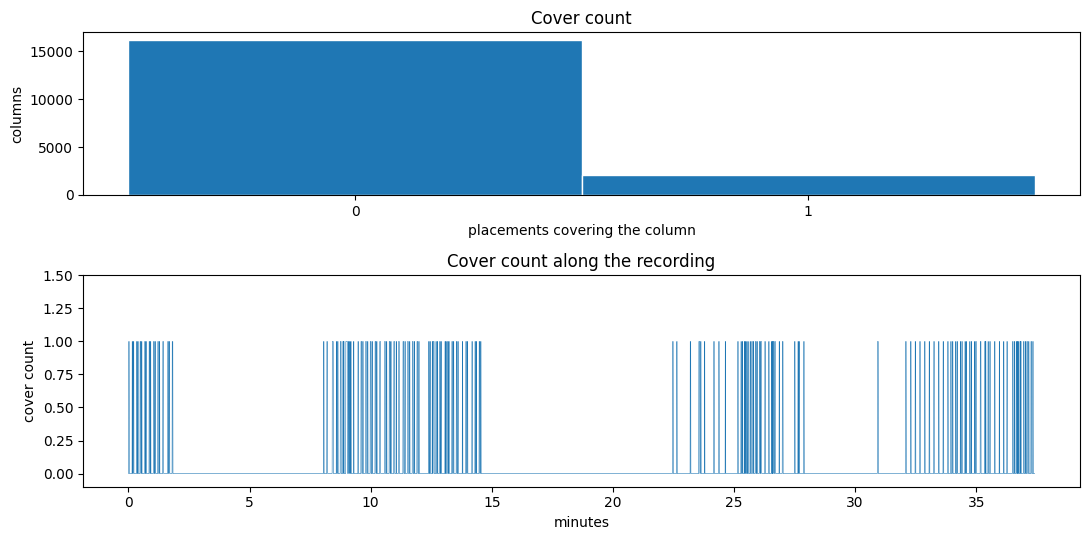

count 0: 16195 columns
count 1: 2075 columns


In [3]:
stacked = np.concatenate([counts[window.window_id] for window in windows])
minutes = np.arange(stacked.size) * sec_per_bin / 60.0
fig, axes = plt.subplots(2, 1, figsize=(11, 5.5), gridspec_kw={"height_ratios": [1, 1.3]})
axes[0].hist(stacked, bins=np.arange(-0.5, 2.5, 1), color="C0", edgecolor="white")
axes[0].set_xticks([0, 1])
axes[0].set_xlabel("placements covering the column")
axes[0].set_ylabel("columns")
axes[0].set_title("Cover count")
axes[1].plot(minutes, stacked, color="C0", lw=0.4)
axes[1].set_xlabel("minutes")
axes[1].set_ylabel("cover count")
axes[1].set_ylim(-0.1, 1.5)
axes[1].set_title("Cover count along the recording")
fig.tight_layout()
plt.show()
for value in (0, 1):
    print(f"count {value}: {int(np.sum(stacked == value))} columns")


## Placements per motif


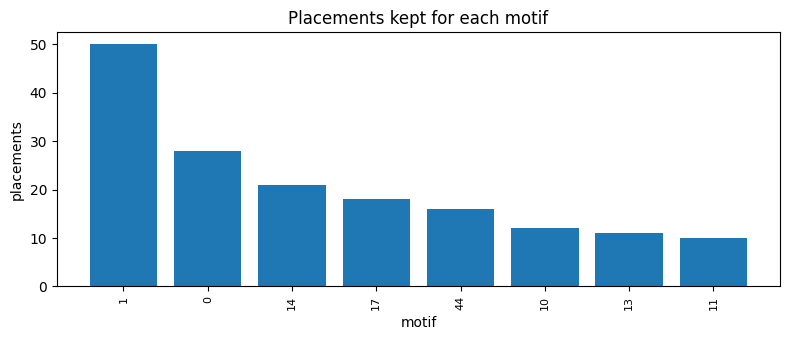

In [4]:
motifs = sorted(summary["motifs"], key=lambda row: -row["n_placements"])
names = [str(row["motif_id"]) for row in motifs]
heights = [row["n_placements"] for row in motifs]
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.bar(np.arange(len(names)), heights, color="C0")
ax.set_xticks(np.arange(len(names)), names, rotation=90, fontsize=8)
ax.set_xlabel("motif")
ax.set_ylabel("placements")
ax.set_title("Placements kept for each motif")
fig.tight_layout()
plt.show()


## Specificity

The dot-product sequence is shifted and scaled by a one-minute Gaussian. The number for a motif is the 90th percentile of its peak-to-baseline ratios. The kernel is the leading component.


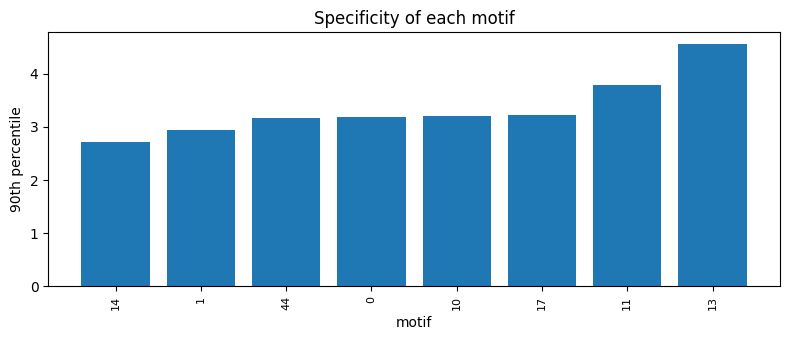

p90  min 2.716  max 4.550
    14  2.7157
     1  2.9328
    44  3.1668
     0  3.1912
    10  3.1979
    17  3.2283
    11  3.7880
    13  4.5497


In [5]:
shift_sigma = 60.0 / sec_per_bin
spec_rows = []
for row in summary["motifs"]:
    kernel = np.load(OUT / row["path"])
    if kernel.ndim == 3:
        kernel = kernel[0]
    ratios, percentile = _specificity_p90(
        _peak_ratios(_dot_products(spectrogram, kernel), float(row["width"] // 2), shift_sigma)
    )
    spec_rows.append((row["motif_id"], float(percentile)))
spec_rows.sort(key=lambda item: item[1])
labels = [str(motif_id) for motif_id, _percentile in spec_rows]
p90 = [percentile for _motif_id, percentile in spec_rows]
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.bar(np.arange(len(labels)), p90, color="C0")
ax.set_xticks(np.arange(len(labels)), labels, rotation=90, fontsize=8)
ax.set_xlabel("motif")
ax.set_ylabel("90th percentile")
ax.set_title("Specificity of each motif")
fig.tight_layout()
plt.show()
print(f"p90  min {min(p90):.3f}  max {max(p90):.3f}")
for motif_id, percentile in spec_rows:
    print(f"  {motif_id:4d}  {percentile:.4f}")


## Motifs

Each panel is the leading principal component, from about 12 Hz to 1500 Hz. The title is the motif index and how many placements it kept.


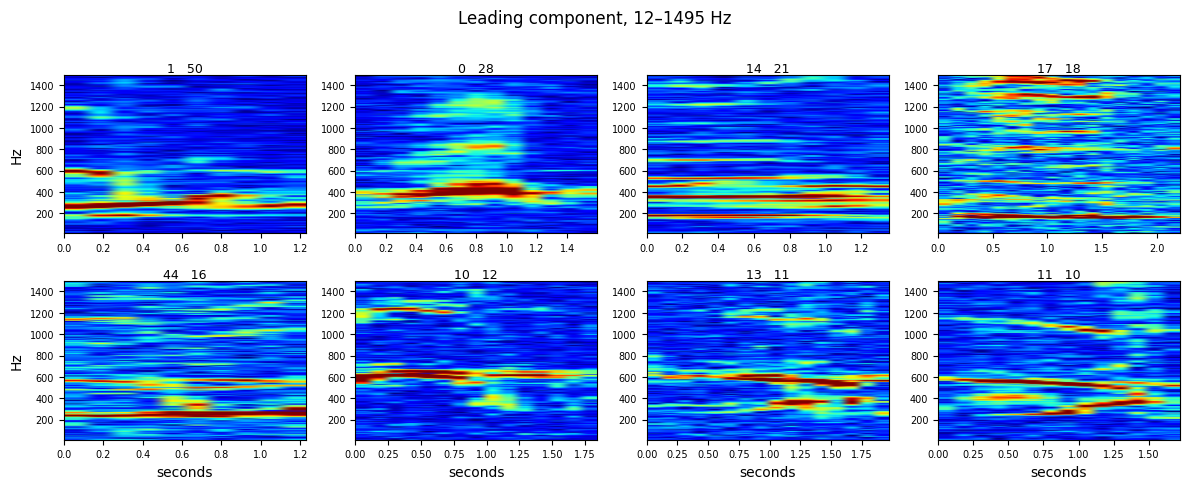

In [6]:
ncols = 4
nrows = int(np.ceil(len(motifs) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(12, 2.4 * nrows))
axes = np.atleast_2d(axes)
for panel, row in enumerate(motifs):
    r, c = divmod(panel, ncols)
    ax = axes[r, c]
    atom = np.load(OUT / row["path"])
    component = atom[0] if atom.ndim == 3 else atom
    shown = display_from_spwhiten(component)[band_lo:band_hi]
    lo, hi = np.percentile(shown, [2, 98])
    extent = [0.0, component.shape[1] * sec_per_bin, f_lo, f_hi]
    ax.imshow(shown, origin="lower", aspect="auto", cmap="jet", vmin=lo, vmax=hi, extent=extent)
    ax.set_title(f"{row['motif_id']}   {row['n_placements']}", fontsize=9, pad=2)
    ax.tick_params(labelsize=7)
    if c == 0:
        ax.set_ylabel("Hz")
    if r == nrows - 1:
        ax.set_xlabel("seconds")
for panel in range(len(motifs), nrows * ncols):
    r, c = divmod(panel, ncols)
    axes[r, c].axis("off")
fig.suptitle(f"Leading component, {f_lo:.0f}–{f_hi:.0f} Hz", y=1.01)
fig.tight_layout()
plt.show()
